In [1]:
import tensorflow as tf
print("TensorFlow version:", tf.__version__)
print("GPUs found:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
GPUs found: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [3]:
!pip install importlib_resources
!rm -rf /root/tensorflow_datasets/plant_village

In [4]:
import tensorflow_datasets as tfds

(train_ds, val_ds, test_ds), info = tfds.load(
    "plant_village",
    split=["train[:80%]", "train[80%:90%]", "train[90%:]"],
    as_supervised=True,
    with_info=True,
)

class_names = info.features["label"].names
print("Number of classes:", len(class_names))
print("First 5 classes:", class_names[:5])
print("Total images:", info.splits["train"].num_examples)

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.Z6IPY1_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.
Number of classes: 38
First 5 classes: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy']
Total images: 54303


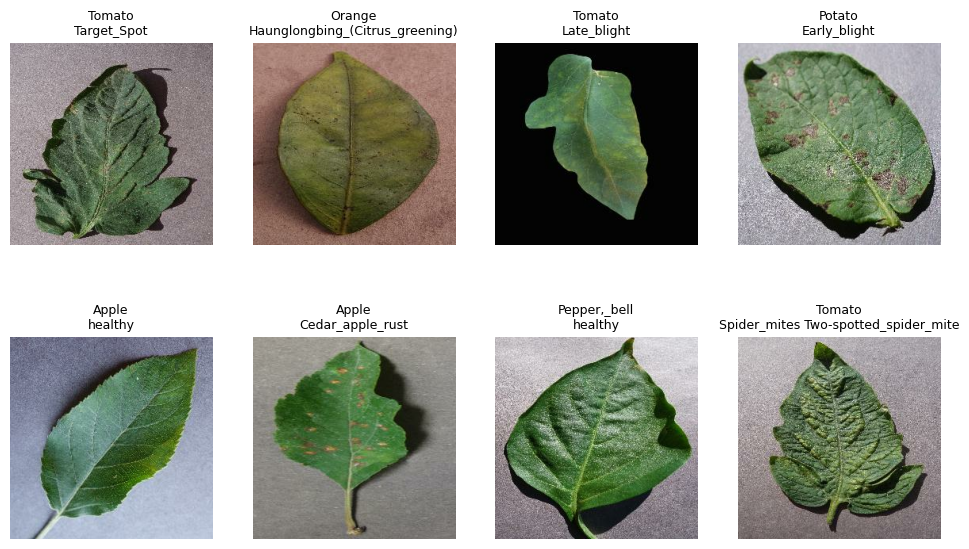

In [5]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 7))
for i, (image, label) in enumerate(train_ds.take(8)):
    plt.subplot(2, 4, i + 1)
    plt.imshow(image.numpy())
    plt.title(class_names[label.numpy()].replace("___", "\n"), fontsize=9)
    plt.axis("off")
plt.show()

In [6]:
IMG_SIZE = 224
BATCH_SIZE = 32
AUTOTUNE = tf.data.AUTOTUNE

def prepare(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    return image, label

train_ds = (train_ds.map(prepare, num_parallel_calls=AUTOTUNE)
            .shuffle(1000).batch(BATCH_SIZE).prefetch(AUTOTUNE))
val_ds = (val_ds.map(prepare, num_parallel_calls=AUTOTUNE)
          .batch(BATCH_SIZE).prefetch(AUTOTUNE))
test_ds = (test_ds.map(prepare, num_parallel_calls=AUTOTUNE)
           .batch(BATCH_SIZE).prefetch(AUTOTUNE))

for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)


In [7]:
from tensorflow import keras
from tensorflow.keras import layers

NUM_CLASSES = len(class_names)

# 1. Random changes to training images, so the model copes with real photos
data_augmentation = keras.Sequential([
    layers.RandomFlip("horizontal_and_vertical"),
    layers.RandomRotation(0.2),
    layers.RandomZoom(0.2),
    layers.RandomContrast(0.2),
], name="augmentation")

# 2. The pretrained MobileNetV2, without its original top layer
base_model = keras.applications.MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet",
)
base_model.trainable = False   # freeze it: keep what it already knows

# 3. Put everything together
inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = layers.Rescaling(1 / 127.5, offset=-1)(x)   # scale pixels to -1..1, as MobileNetV2 expects
x = base_model(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(NUM_CLASSES, activation="softmax")(x)

model = keras.Model(inputs, outputs)

# 4. Tell the model how to learn
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [8]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        "best_model.keras", monitor="val_accuracy", save_best_only=True
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_accuracy", patience=2, restore_best_weights=True
    ),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=callbacks,
)

Epoch 1/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 110s 72ms/step - accuracy: 0.8175 - loss: 0.6470 - val_accuracy: 0.9054 - val_loss: 0.3206
Epoch 2/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 135s 70ms/step - accuracy: 0.8956 - loss: 0.3293 - val_accuracy: 0.9216 - val_loss: 0.2592
Epoch 3/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 96s 70ms/step - accuracy: 0.9005 - loss: 0.3055 - val_accuracy: 0.9227 - val_loss: 0.2336
Epoch 4/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 96s 70ms/step - accuracy: 0.9080 - loss: 0.2808 - val_accuracy: 0.9254 - val_loss: 0.2331
Epoch 5/5
1358/1358 ━━━━━━━━━━━━━━━━━━━━ 95s 70ms/step - accuracy: 0.9114 - loss: 0.2739 - val_accuracy: 0.9168 - val_loss: 0.2409


In [9]:
test_loss, test_acc = model.evaluate(test_ds)
print(f"Test accuracy: {test_acc:.4f}")

170/170 ━━━━━━━━━━━━━━━━━━━━ 10s 60ms/step - accuracy: 0.9335 - loss: 0.2192
Test accuracy: 0.9335


In [10]:
import json

model.save("plant_model.keras")

with open("class_names.json", "w") as f:
    json.dump(class_names, f)

print("Saved!")

Saved!


In [11]:
from google.colab import files
files.download("plant_model.keras")
files.download("class_names.json")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>